In [1]:
# import libraries

import os
import pandas as pd

In [2]:
# Import Libraries for Graph, GNN, and GCN

import stellargraph as sg
from stellargraph import StellarGraph

from stellargraph.mapper import FullBatchNodeGenerator
from stellargraph.layer import GCN

In [3]:
# Machine Learnig related library Imports

from tensorflow.keras import layers, optimizers, losses, metrics, Model
from sklearn import preprocessing, model_selection
from IPython.display import display, HTML
import matplotlib.pyplot as plt
%matplotlib inline


In [4]:
drop_rows_with_na = 1

In [5]:
data = pd.read_csv('D:/paper/onging/data/bank/bankclose.csv')
data

,Date,PAD,SPDB,HXB,CMBC,CMB,CIB,ABC,BOCOM,ICBC,PSBC,CEB,CZB,CCB,BOC,ECITIC
0,2018/1/2,13.70,12.72,9.11,8.52,29.62,17.24,3.85,6.28,6.18,5.61,4.08,4.97,7.79,3.98,6.32
1,2018/1/3,13.33,12.66,9.13,8.58,29.97,17.20,3.88,6.30,6.16,5.61,4.11,4.97,7.75,4.00,6.37
2,2018/1/4,13.25,12.66,9.15,8.54,29.65,17.19,3.87,6.29,6.07,5.61,4.10,4.97,7.61,4.00,6.39
3,2018/1/5,13.30,12.69,9.16,8.60,30.10,17.20,3.87,6.28,6.08,5.61,4.12,4.97,7.68,3.98,6.44
4,2018/1/8,12.96,12.68,9.19,8.72,29.47,17.22,3.86,6.31,6.07,5.61,4.13,4.97,7.59,4.01,6.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1210,2022/12/26,12.77,7.10,5.12,3.40,35.95,17.16,2.85,4.65,4.26,4.42,2.99,2.91,5.50,3.11,4.83
1211,2022/12/27,13.11,7.22,5.18,3.43,36.67,17.43,2.89,4.71,4.30,4.53,3.06,2.94,5.58,3.15,4.90
1212,2022/12/28,13.14,7.30,5.18,3.43,37.33,17.61,2.90,4.75,4.32,4.60,3.06,2.95,5.61,3.16,4.98
1213,2022/12/29,13.03,7.24,5.18,3.43,37.23,17.44,2.88,4.71,4.30,4.56,3.04,2.91,5.59,3.15,4.93


In [6]:
data["Date"] = data["Date"].astype('datetime64[ns]')

In [7]:
data.shape

(1215, 16)

In [8]:
data

,Date,PAD,SPDB,HXB,CMBC,CMB,CIB,ABC,BOCOM,ICBC,PSBC,CEB,CZB,CCB,BOC,ECITIC
0,2018-01-02,13.70,12.72,9.11,8.52,29.62,17.24,3.85,6.28,6.18,5.61,4.08,4.97,7.79,3.98,6.32
1,2018-01-03,13.33,12.66,9.13,8.58,29.97,17.20,3.88,6.30,6.16,5.61,4.11,4.97,7.75,4.00,6.37
2,2018-01-04,13.25,12.66,9.15,8.54,29.65,17.19,3.87,6.29,6.07,5.61,4.10,4.97,7.61,4.00,6.39
3,2018-01-05,13.30,12.69,9.16,8.60,30.10,17.20,3.87,6.28,6.08,5.61,4.12,4.97,7.68,3.98,6.44
4,2018-01-08,12.96,12.68,9.19,8.72,29.47,17.22,3.86,6.31,6.07,5.61,4.13,4.97,7.59,4.01,6.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1210,2022-12-26,12.77,7.10,5.12,3.40,35.95,17.16,2.85,4.65,4.26,4.42,2.99,2.91,5.50,3.11,4.83
1211,2022-12-27,13.11,7.22,5.18,3.43,36.67,17.43,2.89,4.71,4.30,4.53,3.06,2.94,5.58,3.15,4.90
1212,2022-12-28,13.14,7.30,5.18,3.43,37.33,17.61,2.90,4.75,4.32,4.60,3.06,2.95,5.61,3.16,4.98
1213,2022-12-29,13.03,7.24,5.18,3.43,37.23,17.44,2.88,4.71,4.30,4.56,3.04,2.91,5.59,3.15,4.93


In [9]:
# df_s_transpose.index = df_s_transpose['Date']
#data.index = data.index.astype('datetime64[ns]')

# Note: the above data has null and missing values. That will be addressed.

In [10]:
# Experiment find correlations
# Ref: https://towardsdatascience.com/time-series-and-correlations-with-stock-market-data-using-python-e66774e3a16f

In [11]:
df_s_transpose = data.fillna(data.mean())

In [12]:
df_s_transpose

,Date,PAD,SPDB,HXB,CMBC,CMB,CIB,ABC,BOCOM,ICBC,PSBC,CEB,CZB,CCB,BOC,ECITIC
0,2018-01-02,13.70,12.72,9.11,8.52,29.62,17.24,3.85,6.28,6.18,5.61,4.08,4.97,7.79,3.98,6.32
1,2018-01-03,13.33,12.66,9.13,8.58,29.97,17.20,3.88,6.30,6.16,5.61,4.11,4.97,7.75,4.00,6.37
2,2018-01-04,13.25,12.66,9.15,8.54,29.65,17.19,3.87,6.29,6.07,5.61,4.10,4.97,7.61,4.00,6.39
3,2018-01-05,13.30,12.69,9.16,8.60,30.10,17.20,3.87,6.28,6.08,5.61,4.12,4.97,7.68,3.98,6.44
4,2018-01-08,12.96,12.68,9.19,8.72,29.47,17.22,3.86,6.31,6.07,5.61,4.13,4.97,7.59,4.01,6.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1210,2022-12-26,12.77,7.10,5.12,3.40,35.95,17.16,2.85,4.65,4.26,4.42,2.99,2.91,5.50,3.11,4.83
1211,2022-12-27,13.11,7.22,5.18,3.43,36.67,17.43,2.89,4.71,4.30,4.53,3.06,2.94,5.58,3.15,4.90
1212,2022-12-28,13.14,7.30,5.18,3.43,37.33,17.61,2.90,4.75,4.32,4.60,3.06,2.95,5.61,3.16,4.98
1213,2022-12-29,13.03,7.24,5.18,3.43,37.23,17.44,2.88,4.71,4.30,4.56,3.04,2.91,5.59,3.15,4.93


# Pearson Correlation Coefficient

In [13]:
df_s_transpose_pearson = df_s_transpose.corr()
df_s_transpose_pearson

,Date,PAD,SPDB,HXB,CMBC,CMB,CIB,ABC,BOCOM,ICBC,PSBC,CEB,CZB,CCB,BOC,ECITIC
Date,1.000000,0.465637,-0.804942,-0.946433,-0.932140,0.601723,0.422649,-0.918271,-0.856911,-0.855054,-0.584418,-0.724941,-0.954939,-0.777253,-0.868954,-0.881864
PAD,0.465637,1.000000,-0.011124,-0.359457,-0.348780,0.928328,0.829095,-0.359065,-0.542445,-0.170257,0.009720,0.134224,-0.334567,-0.032845,-0.441805,-0.323786
SPDB,-0.804942,-0.011124,1.000000,0.866873,0.863407,-0.227161,-0.005385,0.868233,0.715848,0.905629,0.613047,0.919716,0.865017,0.877382,0.815793,0.844455
HXB,-0.946433,-0.359457,0.866873,1.000000,0.960711,-0.511718,-0.247009,0.970067,0.918190,0.943277,0.621304,0.796201,0.919218,0.892905,0.945285,0.961585
CMBC,-0.932140,-0.348780,0.863407,0.960711,1.000000,-0.522665,-0.288067,0.946107,0.845842,0.929752,0.516899,0.803007,0.875889,0.872726,0.928888,0.931929
CMB,0.601723,0.928328,-0.227161,-0.511718,-0.522665,1.000000,0.811346,-0.514857,-0.626905,-0.344299,-0.011616,-0.090439,-0.498423,-0.206617,-0.580731,-0.493881
CIB,0.422649,0.829095,-0.005385,-0.247009,-0.288067,0.811346,1.000000,-0.226572,-0.314790,-0.050163,0.267806,0.138282,-0.283474,0.109920,-0.267328,-0.180623
ABC,-0.918271,-0.359065,0.868233,0.970067,0.946107,-0.514857,-0.226572,1.000000,0.916335,0.961349,0.620153,0.801522,0.890218,0.911191,0.964603,0.948285
BOCOM,-0.856911,-0.542445,0.715848,0.918190,0.845842,-0.626905,-0.314790,0.916335,1.000000,0.850517,0.601865,0.600592,0.824910,0.786651,0.946321,0.902137
ICBC,-0.855054,-0.170257,0.905629,0.943277,0.929752,-0.344299,-0.050163,0.961349,0.850517,1.000000,0.650595,0.854575,0.848018,0.973207,0.931624,0.938937


# Pearson Correlation Coefficient based Adjacency Graph Matrix

In [14]:
#df_s_transpose_pearson[df_s_transpose_pearson >= 0.5] = 1
#df_s_transpose_pearson[df_s_transpose_pearson < 0.5] = 0
#df_s_transpose_pearson

# Spearman Correlation Coefficient 

In [15]:
df_s_transpose_spearman = df_s_transpose.corr(method='spearman')
df_s_transpose_spearman

,Date,PAD,SPDB,HXB,CMBC,CMB,CIB,ABC,BOCOM,ICBC,PSBC,CEB,CZB,CCB,BOC,ECITIC
Date,1.000000,0.496966,-0.779533,-0.950645,-0.945607,0.637292,0.440567,-0.928168,-0.828095,-0.874716,-0.605983,-0.678192,-0.953051,-0.786625,-0.878846,-0.894448
PAD,0.496966,1.000000,-0.072376,-0.374329,-0.365452,0.947063,0.822216,-0.392097,-0.567642,-0.229705,-0.118592,0.099464,-0.391058,-0.077269,-0.439288,-0.344144
SPDB,-0.779533,-0.072376,1.000000,0.879015,0.891656,-0.249702,-0.017282,0.876300,0.726991,0.921363,0.615274,0.863605,0.827902,0.897132,0.856045,0.868462
HXB,-0.950645,-0.374329,0.879015,1.000000,0.971597,-0.515937,-0.257126,0.969050,0.869929,0.943907,0.684901,0.793000,0.943218,0.886023,0.930702,0.951652
CMBC,-0.945607,-0.365452,0.891656,0.971597,1.000000,-0.513912,-0.282545,0.958752,0.845079,0.936673,0.623235,0.792721,0.930129,0.861409,0.931871,0.939082
CMB,0.637292,0.947063,-0.249702,-0.515937,-0.513912,1.000000,0.833174,-0.524016,-0.627161,-0.381494,-0.176510,-0.088798,-0.536113,-0.226161,-0.554106,-0.485307
CIB,0.440567,0.822216,-0.017282,-0.257126,-0.282545,0.833174,1.000000,-0.237418,-0.294096,-0.076550,0.150549,0.142747,-0.328268,0.087725,-0.246678,-0.185630
ABC,-0.928168,-0.392097,0.876300,0.969050,0.958752,-0.524016,-0.237418,1.000000,0.899018,0.957881,0.682060,0.782519,0.915013,0.892844,0.959257,0.945675
BOCOM,-0.828095,-0.567642,0.726991,0.869929,0.845079,-0.627161,-0.294096,0.899018,1.000000,0.841417,0.657486,0.546849,0.804681,0.751228,0.934691,0.861924
ICBC,-0.874716,-0.229705,0.921363,0.943907,0.936673,-0.381494,-0.076550,0.957881,0.841417,1.000000,0.724887,0.841425,0.888386,0.962041,0.928537,0.952599


# Spearman Correlation Coefficient based Adjacency Graph Matrix

# Find Kendall Correlation Coefficient

In [16]:
df_s_transpose_kendall = df_s_transpose.corr(method='kendall')
df_s_transpose_kendall

,Date,PAD,SPDB,HXB,CMBC,CMB,CIB,ABC,BOCOM,ICBC,PSBC,CEB,CZB,CCB,BOC,ECITIC
Date,1.000000,0.333327,-0.604706,-0.806037,-0.826947,0.454362,0.280955,-0.757249,-0.619109,-0.681655,-0.440140,-0.506062,-0.838414,-0.592473,-0.679573,-0.690712
PAD,0.333327,1.000000,0.025042,-0.200365,-0.206357,0.803294,0.638060,-0.232030,-0.359386,-0.121168,-0.062413,0.097320,-0.243956,-0.030493,-0.278970,-0.200353
SPDB,-0.604706,0.025042,1.000000,0.717950,0.741456,-0.104333,0.045914,0.695918,0.521701,0.764278,0.459102,0.716081,0.694145,0.723086,0.654675,0.684927
HXB,-0.806037,-0.200365,0.717950,1.000000,0.862551,-0.311465,-0.130001,0.855666,0.701441,0.802657,0.509230,0.633489,0.815620,0.723241,0.783496,0.809739
CMBC,-0.826947,-0.206357,0.741456,0.862551,1.000000,-0.318639,-0.143980,0.828868,0.655874,0.791752,0.460359,0.630413,0.814678,0.703520,0.785489,0.785389
CMB,0.454362,0.803294,-0.104333,-0.311465,-0.318639,1.000000,0.647940,-0.335493,-0.413995,-0.222014,-0.098866,-0.016253,-0.368045,-0.129290,-0.369410,-0.307584
CIB,0.280955,0.638060,0.045914,-0.130001,-0.143980,0.647940,1.000000,-0.113620,-0.179388,-0.017309,0.114494,0.122469,-0.207432,0.079254,-0.129933,-0.097300
ABC,-0.757249,-0.232030,0.695918,0.855666,0.828868,-0.335493,-0.113620,1.000000,0.734245,0.835354,0.511618,0.598513,0.751899,0.745126,0.835208,0.806544
BOCOM,-0.619109,-0.359386,0.521701,0.701441,0.655874,-0.413995,-0.179388,0.734245,1.000000,0.646972,0.483751,0.420113,0.601561,0.577126,0.791881,0.675189
ICBC,-0.681655,-0.121168,0.764278,0.802657,0.791752,-0.222014,-0.017309,0.835354,0.646972,1.000000,0.556145,0.670478,0.719760,0.847146,0.770879,0.815424


In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [18]:
rc = {'font.sans-serif': 'SimHei',
      'axes.unicode_minus': False}
sns.set(font_scale=0.7,rc=rc) 

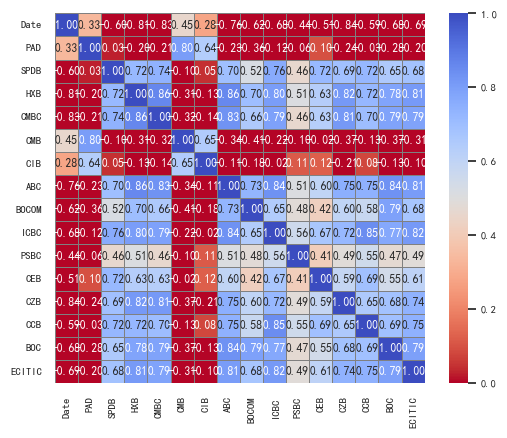

In [19]:
sns.heatmap(df_s_transpose_kendall,
            annot=True,  # 显示相关系数的数据
            center=0.5,  # 居中
            fmt='.2f',  # 只显示两位小数
            linewidth=0.5,  # 设置每个单元格的距离
            linecolor='grey',  # 设置间距线的颜色
            vmin=0, vmax=1,  # 设置数值最小值和最大值
            xticklabels=True, yticklabels=True,  # 显示x轴和y轴
            square=True,  # 每个方格都是正方形
            cbar=True,  # 绘制颜色条
            cmap='coolwarm_r',  # 设置热力图颜色
            )
plt.ion() #显示图片

C:\Users\perfe\AppData\Local\Temp\ipykernel_1604\2613602815.py:47: UserWarning: Glyph 38134 (\N{CJK UNIFIED IDEOGRAPH-94F6}) missing from current font.
  plt.tight_layout()
C:\Users\perfe\AppData\Local\Temp\ipykernel_1604\2613602815.py:47: UserWarning: Glyph 34892 (\N{CJK UNIFIED IDEOGRAPH-884C}) missing from current font.
  plt.tight_layout()
C:\Users\perfe\AppData\Local\Temp\ipykernel_1604\2613602815.py:47: UserWarning: Glyph 30456 (\N{CJK UNIFIED IDEOGRAPH-76F8}) missing from current font.
  plt.tight_layout()
C:\Users\perfe\AppData\Local\Temp\ipykernel_1604\2613602815.py:47: UserWarning: Glyph 20851 (\N{CJK UNIFIED IDEOGRAPH-5173}) missing from current font.
  plt.tight_layout()
C:\Users\perfe\AppData\Local\Temp\ipykernel_1604\2613602815.py:47: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from current font.
  plt.tight_layout()
C:\Users\perfe\AppData\Local\Temp\ipykernel_1604\2613602815.py:47: UserWarning: Glyph 28909 (\N{CJK UNIFIED IDEOGRAPH-70ED}) missing fr

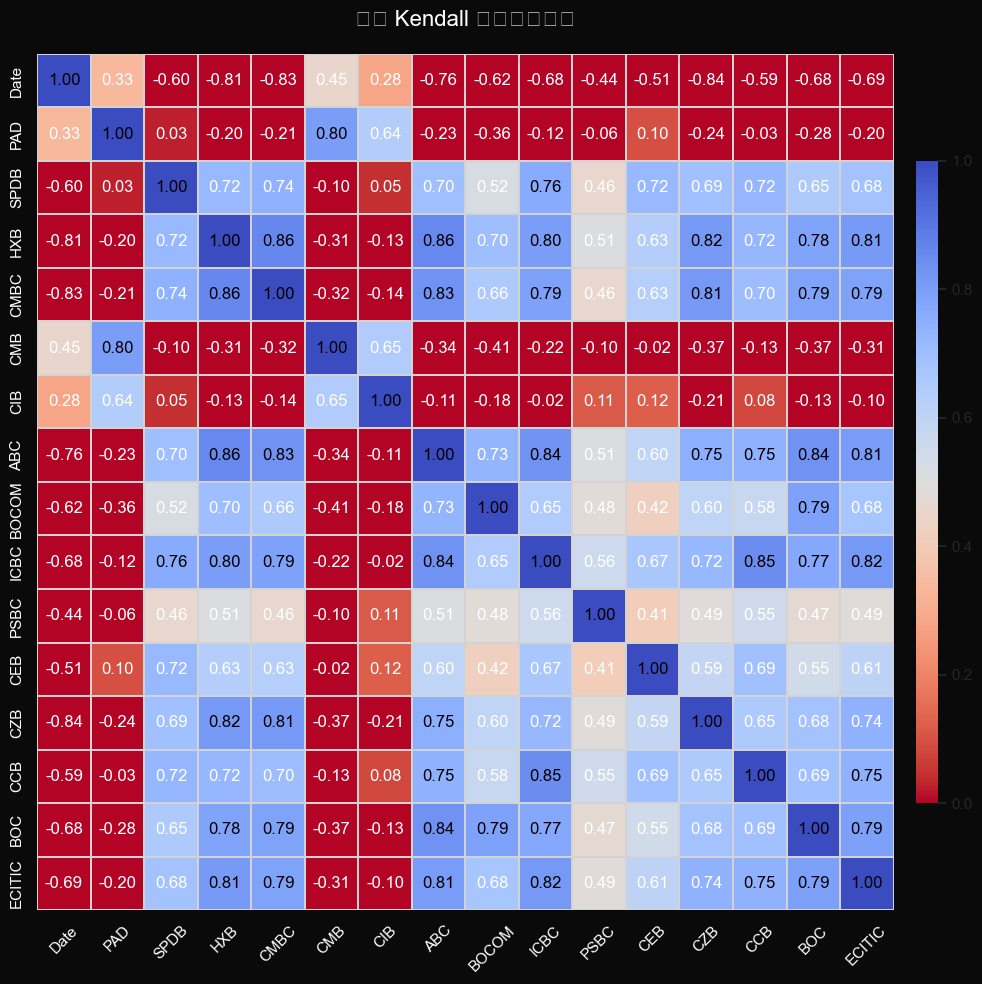

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# 设置全局深色风格（也可以尝试 'dark', 'whitegrid'）
sns.set(style='dark')

plt.figure(figsize=(12, 10))
ax = sns.heatmap(
    df_s_transpose_kendall,
    annot=True,
    fmt='.2f',
    center=0.5,
    square=True,
    linewidth=0.3,
    linecolor='lightgrey',
    xticklabels=True,
    yticklabels=True,
    vmin=0,
    vmax=1,
    cmap='coolwarm_r',  # 可以替换为 'rocket', 'viridis', 'magma', 'plasma'
    cbar=True,
    cbar_kws={
        'shrink': 0.75,
        'aspect': 30,
        'orientation': 'vertical',
        'pad': 0.02
    }
)

# 设置背景黑色，字体白色
plt.gcf().set_facecolor('#0a0a0a')
ax.set_facecolor('#0a0a0a')

# 设置刻度标签颜色和样式
ax.tick_params(axis='x', colors='white', labelrotation=45)
ax.tick_params(axis='y', colors='white')

# 设置标题（如果有）
plt.title("银行 Kendall 相关性热力图", fontsize=16, color='white', pad=20)

# 调整注释字体颜色
for text in ax.texts:
    val = float(text.get_text())
    text.set_color('white' if val < 0.75 else 'black')  # 背景深色上改白字

# 强制刷新图像
plt.tight_layout()
plt.savefig("D:/paper/onging/bankgraph/heatmap_kendall.svg", format='svg', dpi=300)
plt.show()


In [18]:
df_s_transpose_kendall.shape

(15, 15)

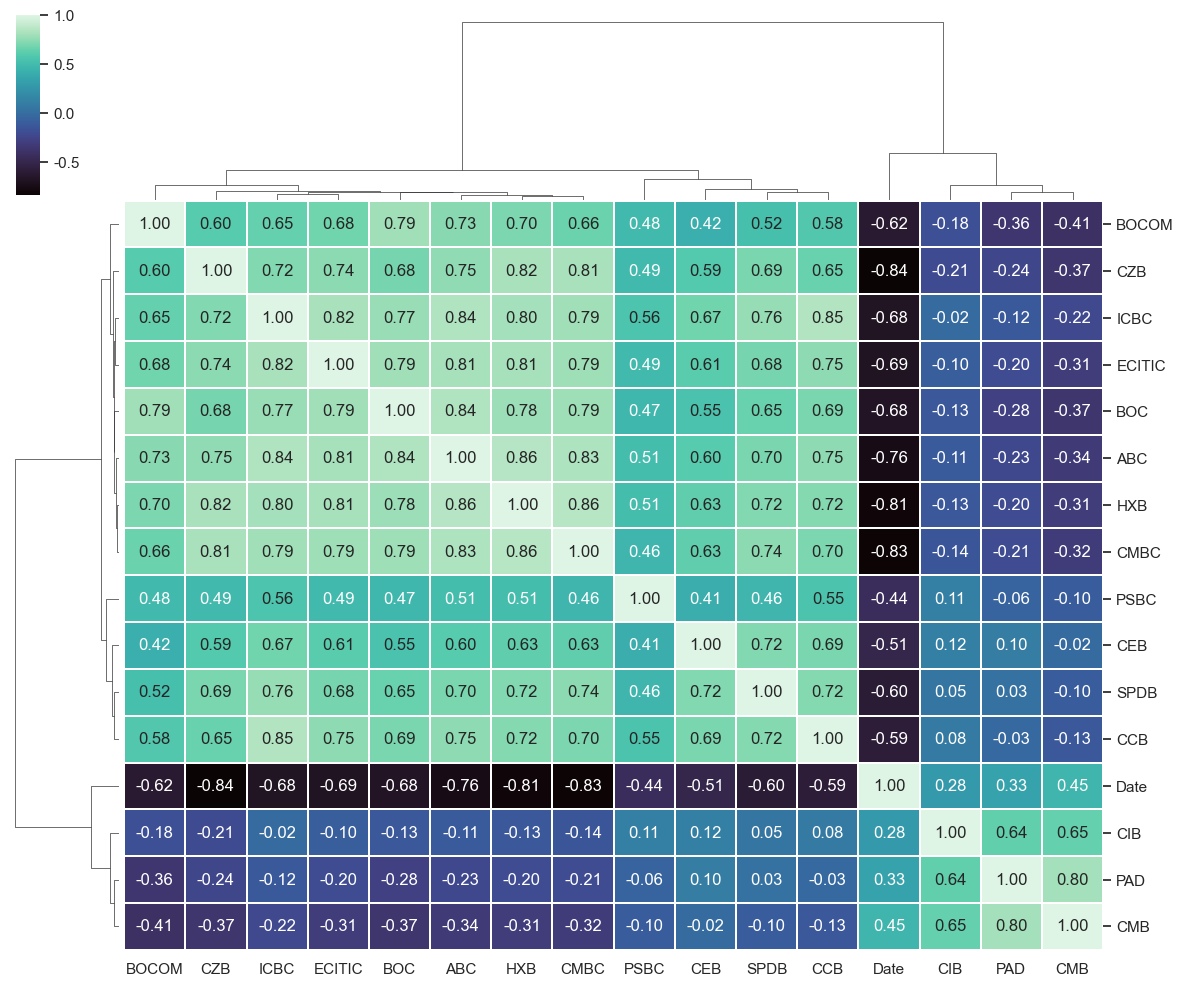

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style='white')  # 干净背景
g = sns.clustermap(
    df_s_transpose_kendall,
    method='ward',  # 层次聚类方式，可选：'average'、'single'、'complete'
    metric='euclidean',  # 距离度量方式
    cmap='mako',  # 蓝绿渐变色更具科技感
    linewidth=0.2,
    figsize=(12, 10),
    annot=True,
    fmt='.2f',
    xticklabels=True,
    yticklabels=True,
    cbar_pos=(0.02, 0.8, 0.02, 0.18),  # 色条位置 [left, bottom, width, height]
    dendrogram_ratio=(.1, .2),  # 聚类树图占比
)

#plt.suptitle("Bank Group Turnover Kendall Correlation", fontsize=16, color='black')
plt.savefig("D:/paper/onging/bankgraph/bankheatmap_clustermap.svg", format='svg', dpi=300)
plt.show()


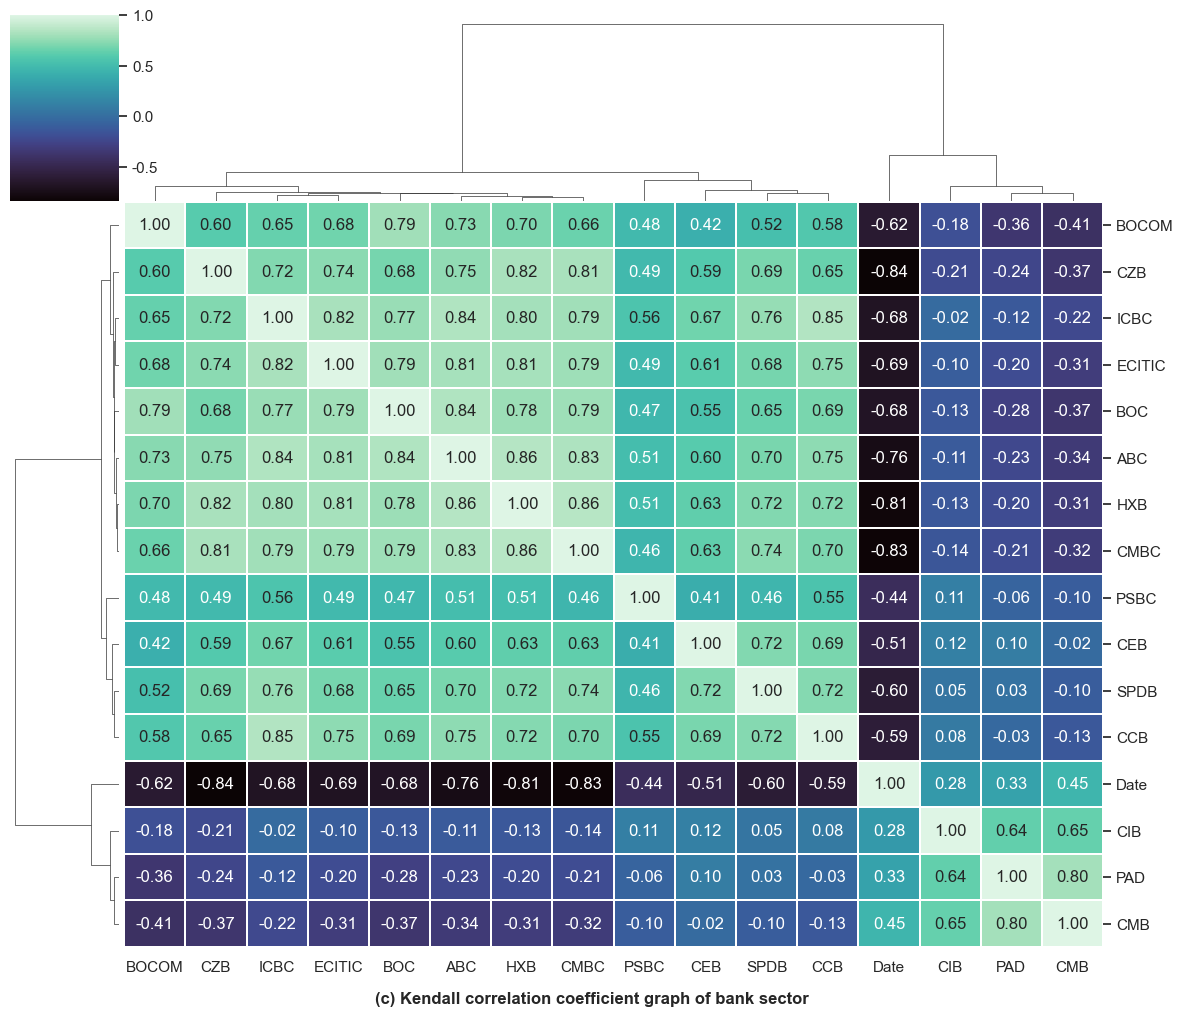

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style='white')  # 干净背景
g = sns.clustermap(
    df_s_transpose_kendall,
    method='ward',          # 层次聚类方式
    metric='euclidean',     # 距离度量方式
    cmap='mako',            # 蓝绿渐变色
    linewidth=0.2,
    figsize=(12, 10),
    annot=True,
    fmt='.2f',
    xticklabels=True,
    yticklabels=True,
    cbar_pos=(0.02, 0.8, 0.02, 0.18),  # 色条位置 [left, bottom, width, height]
    dendrogram_ratio=(.1, .2),         # 聚类树图占比
)

# 在整张图下方添加文字
g.fig.subplots_adjust(bottom=0.05)  # 预留底部空间
g.fig.text(
    0.5, -0.01,
    '(c) Kendall correlation coefficient graph of bank sector',
    ha='center', va='bottom',
    fontsize=12, fontweight='bold'
)

# 保存图像
g.fig.savefig(
    "D:/paper/onging/bankgraph/bankheatmap_clustermap.svg",
    format='svg', dpi=300, bbox_inches='tight', pad_inches=0.2
)

plt.show()


# Kendall Correlation Coefficient based Adjacency Graph Matrix

Create and visualize the Graphs

In [19]:
import networkx as nx
Graph_pearson = nx.Graph(df_s_transpose_pearson)

In [20]:
Graph_spearman = nx.Graph(df_s_transpose_spearman)
Graph_kendall = nx.Graph(df_s_transpose_kendall)

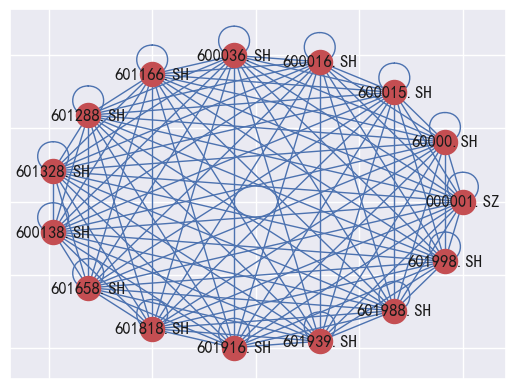

In [21]:
nx.draw_networkx(Graph_kendall, pos=nx.circular_layout(Graph_kendall), node_color='r', edge_color='b')

In [21]:
Graph_pearson

In [22]:
import numpy as np

In [23]:
#np.save("D:/paper/onging/bankgraph/bankvolume_spearman.npy",df_s_transpose_spearman)

In [24]:
#np.save("D:/paper/onging/bankgraph/bankvolume_kendall.npy",df_s_transpose_kendall)

In [25]:
#np.save("D:/paper/onging/bankgraph/bankvolume_pearson.npy",df_s_transpose_pearson)

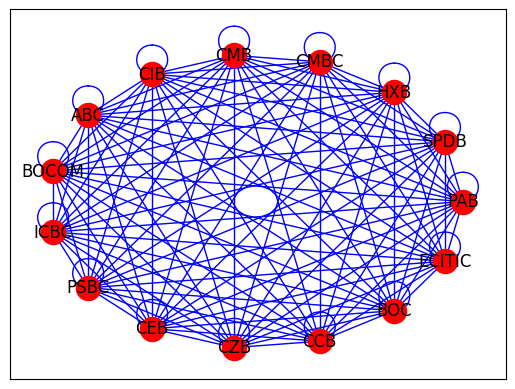

In [26]:
nx.draw_networkx(Graph_spearman, pos=nx.circular_layout(Graph_spearman), node_color='r', edge_color='b')

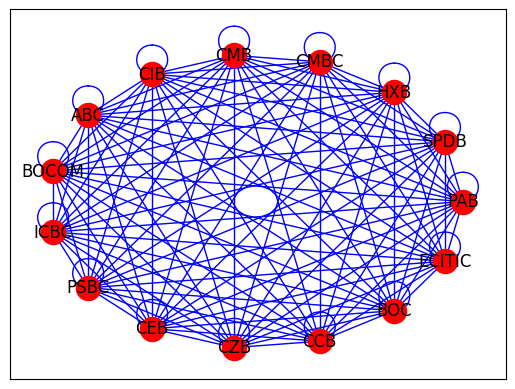

In [27]:
nx.draw_networkx(Graph_kendall, pos=nx.circular_layout(Graph_kendall), node_color='r', edge_color='b')

# Create GCN layer. Pearson

# Find all stocks = nodes

In [28]:
# improvement: make sure only stocks/nodes that are in the graph are taken
all_stock_nodes = df_s_transpose_pearson.index.to_list()
all_stock_nodes

['PAB',
 'SPDB',
 'HXB',
 'CMBC',
 'CMB',
 'CIB',
 'ABC',
 'BOCOM',
 'ICBC',
 'PSBC',
 'CEB',
 'CZB',
 'CCB',
 'BOC',
 'ECITIC']

# Find all edges between nodes

In [29]:
source = [];
target = [];
edge_feature = [];

for aStock in all_stock_nodes:
    for anotherStock in all_stock_nodes:
        if df_s_transpose_pearson[aStock][anotherStock] > 0:
            #print(df_s_transpose_pearson[aStock][anotherStock])
            source.append(aStock)
            target.append(anotherStock)
            edge_feature.append(1)
            
source, target, edge_feature            

(['PAB',
  'PAB',
  'PAB',
  'PAB',
  'PAB',
  'PAB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'SPDB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'HXB',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMBC',
  'CMB',
  'CMB',
  'CMB',
  'CMB',
  'CMB',
  'CIB',
  'CIB',
  'CIB',
  'CIB',
  'CIB',
  'CIB',
  'CIB',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'ABC',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'BOCOM',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'ICBC',
  'PSBC',
  'PSBC',
  'PSBC',
  'PSBC',
  'PSBC',
  'PSBC',
  'PSBC',
  'PSBC',
  'PSBC',
  'PSBC',
  'PSBC',
  'PSBC',
  'PSBC',


In [30]:
# https://stellargraph.readthedocs.io/en/stable/demos/basics/loading-pandas.html
pearson_edges = pd.DataFrame(
    {"source": source, "target": target}
)

pearson_edges_data = pd.DataFrame(
    {"source": source, "target": target, "edge_feature": edge_feature}
)


pearson_edges[:10]

,source,target
0,PAB,PAB
1,PAB,CMB
2,PAB,CIB
3,PAB,PSBC
4,PAB,CEB
5,PAB,CZB
6,SPDB,SPDB
7,SPDB,HXB
8,SPDB,CMBC
9,SPDB,ABC


In [31]:
# Graph with No Feature Data, No node data, only edges

pearson_graph = StellarGraph(edges = pearson_edges, node_type_default="corner", edge_type_default="line")
#pearson_graph = StellarGraph(nodes = all_stock_nodes, edges = pearson_edges)
# graph = sg.StellarGraph(all_stock_nodes, square_edges)
print(pearson_graph.info())

In [32]:
# Trying to have the time series data as part of the nodes

In [33]:
print(df_s_transpose_pearson.info())

<class 'pandas.core.frame.DataFrame'>
Index: 15 entries, PAB to ECITIC
Data columns (total 15 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   PAB     15 non-null     float64
 1   SPDB    15 non-null     float64
 2   HXB     15 non-null     float64
 3   CMBC    15 non-null     float64
 4   CMB     15 non-null     float64
 5   CIB     15 non-null     float64
 6   ABC     15 non-null     float64
 7   BOCOM   15 non-null     float64
 8   ICBC    15 non-null     float64
 9   PSBC    15 non-null     float64
 10  CEB     15 non-null     float64
 11  CZB     15 non-null     float64
 12  CCB     15 non-null     float64
 13  BOC     15 non-null     float64
 14  ECITIC  15 non-null     float64
dtypes: float64(15)
memory usage: 2.4+ KB
None


In [34]:
df_s_transpose

,Date,PAB,SPDB,HXB,CMBC,CMB,CIB,ABC,BOCOM,ICBC,PSBC,CEB,CZB,CCB,BOC,ECITIC
0,2018-01-02,13.70,12.72,9.11,8.52,29.62,17.24,3.85,6.28,6.18,5.109785,4.08,3.763674,7.79,3.98,6.32
1,2018-01-03,13.33,12.66,9.13,8.58,29.97,17.20,3.88,6.30,6.16,5.109785,4.11,3.763674,7.75,4.00,6.37
2,2018-01-04,13.25,12.66,9.15,8.54,29.65,17.19,3.87,6.29,6.07,5.109785,4.10,3.763674,7.61,4.00,6.39
3,2018-01-05,13.30,12.69,9.16,8.60,30.10,17.20,3.87,6.28,6.08,5.109785,4.12,3.763674,7.68,3.98,6.44
4,2018-01-08,12.96,12.68,9.19,8.72,29.47,17.22,3.86,6.31,6.07,5.109785,4.13,3.763674,7.59,4.01,6.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1210,2022-12-26,12.77,7.10,5.12,3.40,35.95,17.16,2.85,4.65,4.26,4.420000,2.99,2.910000,5.50,3.11,4.83
1211,2022-12-27,13.11,7.22,5.18,3.43,36.67,17.43,2.89,4.71,4.30,4.530000,3.06,2.940000,5.58,3.15,4.90
1212,2022-12-28,13.14,7.30,5.18,3.43,37.33,17.61,2.90,4.75,4.32,4.600000,3.06,2.950000,5.61,3.16,4.98
1213,2022-12-29,13.03,7.24,5.18,3.43,37.23,17.44,2.88,4.71,4.30,4.560000,3.04,2.910000,5.59,3.15,4.93


# Structure the Feature Matrix so that it can be passed to the GCN

In [35]:
df_s_transpose_feature = df_s_transpose.reset_index(drop = True, inplace=False)
#df_s_transpose_feature =  df_s_transpose.values.tolist()
# print(df_s_transpose_feature)
df_s_transpose_feature['PAB'].values

array([13.7 , 13.33, 13.25, ..., 13.14, 13.03, 13.16])

In [36]:
np.sum(df_s_transpose_feature).dtype

C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\numpy\core\fromnumeric.py:84: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  return reduction(axis=axis, out=out, **passkwargs)


dtype('float64')

In [37]:
#print(df_s_transpose_feature)


In [38]:
node_Data = [];
for x in all_stock_nodes:
    node_Data.append( df_s_transpose_feature[x].values)
    
    
node_Data    

[array([13.7 , 13.33, 13.25, ..., 13.14, 13.03, 13.16]),
 array([12.72, 12.66, 12.66, ...,  7.3 ,  7.24,  7.28]),
 array([9.11, 9.13, 9.15, ..., 5.18, 5.18, 5.19]),
 array([8.52, 8.58, 8.54, ..., 3.43, 3.43, 3.45]),
 array([29.62, 29.97, 29.65, ..., 37.33, 37.23, 37.26]),
 array([17.24, 17.2 , 17.19, ..., 17.61, 17.44, 17.59]),
 array([3.85, 3.88, 3.87, ..., 2.9 , 2.88, 2.91]),
 array([6.28, 6.3 , 6.29, ..., 4.75, 4.71, 4.74]),
 array([6.18, 6.16, 6.07, ..., 4.32, 4.3 , 4.34]),
 array([5.10978495, 5.10978495, 5.10978495, ..., 4.6       , 4.56      ,
        4.62      ]),
 array([4.08, 4.11, 4.1 , ..., 3.06, 3.04, 3.07]),
 array([3.76367374, 3.76367374, 3.76367374, ..., 2.95      , 2.91      ,
        2.94      ]),
 array([7.79, 7.75, 7.61, ..., 5.61, 5.59, 5.63]),
 array([3.98, 4.  , 4.  , ..., 3.16, 3.15, 3.16]),
 array([6.32, 6.37, 6.39, ..., 4.98, 4.93, 4.98])]

In [39]:
pearson_graph_node_data = pd.DataFrame(node_Data, index = all_stock_nodes)
pearson_graph_node_data

,0,1,2,3,4,5,6,7,8,9,...,1205,1206,1207,1208,1209,1210,1211,1212,1213,1214
PAB,13.700000,13.330000,13.250000,13.300000,12.960000,13.080000,13.470000,13.400000,13.550000,14.200000,...,13.04,12.76,12.89,12.95,12.98,12.77,13.11,13.14,13.03,13.16
SPDB,12.720000,12.660000,12.660000,12.690000,12.680000,12.700000,13.020000,12.940000,12.910000,13.020000,...,7.24,7.14,7.19,7.24,7.19,7.10,7.22,7.30,7.24,7.28
HXB,9.110000,9.130000,9.150000,9.160000,9.190000,9.190000,9.350000,9.290000,9.360000,9.400000,...,5.22,5.17,5.17,5.17,5.12,5.12,5.18,5.18,5.18,5.19
CMBC,8.520000,8.580000,8.540000,8.600000,8.720000,8.680000,8.820000,8.800000,8.800000,8.870000,...,3.45,3.42,3.42,3.43,3.41,3.40,3.43,3.43,3.43,3.45
CMB,29.620000,29.970000,29.650000,30.100000,29.470000,29.770000,30.530000,30.920000,31.510000,31.940000,...,36.50,35.72,35.95,36.50,36.37,35.95,36.67,37.33,37.23,37.26
CIB,17.240000,17.200000,17.190000,17.200000,17.220000,17.180000,18.180000,18.030000,17.930000,18.000000,...,17.33,16.98,17.11,17.26,17.25,17.16,17.43,17.61,17.44,17.59
ABC,3.850000,3.880000,3.870000,3.870000,3.860000,3.830000,3.910000,3.990000,4.010000,4.120000,...,2.88,2.85,2.85,2.86,2.87,2.85,2.89,2.90,2.88,2.91
BOCOM,6.280000,6.300000,6.290000,6.280000,6.310000,6.280000,6.320000,6.350000,6.370000,6.480000,...,4.70,4.66,4.66,4.69,4.68,4.65,4.71,4.75,4.71,4.74
ICBC,6.180000,6.160000,6.070000,6.080000,6.070000,6.090000,6.160000,6.210000,6.250000,6.430000,...,4.26,4.23,4.25,4.27,4.25,4.26,4.30,4.32,4.30,4.34
PSBC,5.109785,5.109785,5.109785,5.109785,5.109785,5.109785,5.109785,5.109785,5.109785,5.109785,...,4.56,4.46,4.48,4.46,4.43,4.42,4.53,4.60,4.56,4.62


In [40]:
np.sum(pearson_graph_node_data).dtype

dtype('float64')

# Graph with feature as part of Nodes

In [41]:
pearson_graph_with_node_features = StellarGraph(pearson_graph_node_data, edges = pearson_edges, node_type_default="corner", edge_type_default="line")
print(pearson_graph_with_node_features.info())


StellarGraph: Undirected multigraph
 Nodes: 15, Edges: 171

 Node types:
  corner: [15]
    Features: float32 vector, length 1215
    Edge types: corner-line->corner

 Edge types:
    corner-line->corner: [171]
        Weights: all 1 (default)
        Features: none


In [42]:
# Generator
generator = FullBatchNodeGenerator(pearson_graph_with_node_features, method = "gcn")

Using GCN (local pooling) filters...


No need for this block

Graph with feature as part of both Nodes and edges
although Edge data is not required


pearson_graph_with_edge_features = StellarGraph(pearson_graph_node_data, edges = pearson_edges, node_type_default="corner", edge_type_default="line")
print(pearson_graph_with_edge_features.info())
generator = FullBatchNodeGenerator(pearson_graph_with_edge_features, method = "gcn")

In [43]:
# Train Test Split

In [44]:
train_subjects, test_subjects = model_selection.train_test_split(
    pearson_graph_node_data#, train_size = 6, test_size = 4
)
# , train_size=6, test_size=None, stratify=pearson_graph_node_data

val_subjects, test_subjects_ = model_selection.train_test_split(
    test_subjects #, test_size = 2
)

#, train_size=500, test_size=None, stratify=test_subjects

#val_subjects, test_subjects = model_selection.train_test_split(
#    test_subjects, train_size=500, test_size=None, stratify=test_subjects
#)

train_subjects.shape, test_subjects.shape, val_subjects.shape, test_subjects_.shape

((11, 1215), (4, 1215), (3, 1215), (1, 1215))

In [45]:
pearson_graph_node_data

,0,1,2,3,4,5,6,7,8,9,...,1205,1206,1207,1208,1209,1210,1211,1212,1213,1214
PAB,13.700000,13.330000,13.250000,13.300000,12.960000,13.080000,13.470000,13.400000,13.550000,14.200000,...,13.04,12.76,12.89,12.95,12.98,12.77,13.11,13.14,13.03,13.16
SPDB,12.720000,12.660000,12.660000,12.690000,12.680000,12.700000,13.020000,12.940000,12.910000,13.020000,...,7.24,7.14,7.19,7.24,7.19,7.10,7.22,7.30,7.24,7.28
HXB,9.110000,9.130000,9.150000,9.160000,9.190000,9.190000,9.350000,9.290000,9.360000,9.400000,...,5.22,5.17,5.17,5.17,5.12,5.12,5.18,5.18,5.18,5.19
CMBC,8.520000,8.580000,8.540000,8.600000,8.720000,8.680000,8.820000,8.800000,8.800000,8.870000,...,3.45,3.42,3.42,3.43,3.41,3.40,3.43,3.43,3.43,3.45
CMB,29.620000,29.970000,29.650000,30.100000,29.470000,29.770000,30.530000,30.920000,31.510000,31.940000,...,36.50,35.72,35.95,36.50,36.37,35.95,36.67,37.33,37.23,37.26
CIB,17.240000,17.200000,17.190000,17.200000,17.220000,17.180000,18.180000,18.030000,17.930000,18.000000,...,17.33,16.98,17.11,17.26,17.25,17.16,17.43,17.61,17.44,17.59
ABC,3.850000,3.880000,3.870000,3.870000,3.860000,3.830000,3.910000,3.990000,4.010000,4.120000,...,2.88,2.85,2.85,2.86,2.87,2.85,2.89,2.90,2.88,2.91
BOCOM,6.280000,6.300000,6.290000,6.280000,6.310000,6.280000,6.320000,6.350000,6.370000,6.480000,...,4.70,4.66,4.66,4.69,4.68,4.65,4.71,4.75,4.71,4.74
ICBC,6.180000,6.160000,6.070000,6.080000,6.070000,6.090000,6.160000,6.210000,6.250000,6.430000,...,4.26,4.23,4.25,4.27,4.25,4.26,4.30,4.32,4.30,4.34
PSBC,5.109785,5.109785,5.109785,5.109785,5.109785,5.109785,5.109785,5.109785,5.109785,5.109785,...,4.56,4.46,4.48,4.46,4.43,4.42,4.53,4.60,4.56,4.62


In [46]:
np.sum(pearson_graph_node_data).dtype

dtype('float64')

In [47]:
np.sum(train_subjects).dtype

dtype('float64')

In [48]:
train_targets = train_subjects; 
val_targets = val_subjects; 
test_targets = test_subjects; 

In [49]:
train_gen = generator.flow(train_subjects.index, train_targets)

In [50]:
import tensorflow as tf

# This was there, but for classification, model does not match. I am changing
gcn = GCN(
    layer_sizes=[16, 16], activations=["relu", "relu"], generator=generator , dropout=0.5
)
x_inp, x_out = gcn.in_out_tensors()
predictions = layers.Dense(units=train_targets.shape[1], activation="softmax")(x_out)


In [66]:
from tensorflow.keras.layers import Dense, Conv1D, MaxPool1D, Dropout, Flatten
from tensorflow import keras

# layer_sizes = [32, 1, 32, 1, 32, 1]
# activations = ["relu", 'linear', "relu", 'linear',"relu", 'linear']

layer_sizes = [32]
activations = ["relu"]

gcn = GCN(layer_sizes = layer_sizes, activations = activations, generator = generator) #, dropout = 0.5
x_inp, x_out = gcn.in_out_tensors()

#x_out = Conv1D(filters = 2, kernel_size = 2)(x_out)
#x_out = MaxPool1D(pool_size=2)(x_out)
#x_out = Conv1D(filters = 32, kernel_size = sum(layer_sizes))(x_out)
#prediction = keras.layers.Reshape((-1,))(prediction)
#x_out = keras.layers.Reshape((1,16))(x_out)
#x_out = GCN(layer_sizes = layer_sizes, activations = activations, generator = generator)(x_out) #, dropout = 0.5

# predictions = layers.Dense(units=train_targets.shape[1], activation="softmax")(x_out)
predictions = layers.Dense(units = train_targets.shape[1], activation = "relu",dtype=tf.float32)(x_out)
x_out, 
x_inp, x_out

([<KerasTensor: shape=(1, 15, 1215) dtype=float32 (created by layer 'input_13')>,
  <KerasTensor: shape=(1, None) dtype=int32 (created by layer 'input_14')>,
  <KerasTensor: shape=(1, None, 2) dtype=int64 (created by layer 'input_15')>,
  <KerasTensor: shape=(1, None) dtype=float32 (created by layer 'input_16')>],
 <KerasTensor: shape=(1, None, 32) dtype=float32 (created by layer 'gather_indices_3')>)

# Experiment with Models

In [67]:
from tensorflow.keras.layers import Dense, Conv1D, MaxPool1D, Dropout, Flatten
from tensorflow import keras

# layer_sizes = [32, 1, 32, 1, 32, 1]
# activations = ["relu", 'linear', "relu", 'linear',"relu", 'linear']

layer_sizes = [32, 32]
activations = ["relu", "relu"]

gcn = GCN(layer_sizes = layer_sizes, activations = activations, generator = generator) #, dropout = 0.5
x_inp, x_out = gcn.in_out_tensors()
xout = x_out

#x_out = Conv1D(filters = 7, kernel_size = 7)(x_out)
input_shape = (4, 10, 128)
x_out = Conv1D(32, 3, activation = 'relu', input_shape = x_out[1:])(x_out)
#x_out = MaxPool1D(pool_size=2)(x_out)
#x_out = Conv1D(filters = 32, kernel_size = sum(layer_sizes))(x_out)
#prediction = keras.layers.Reshape((-1,))(prediction)
#x_out = keras.layers.Reshape((1,16))(x_out)

# Generator
#generator2 = FullBatchNodeGenerator(x_out, method = "gcn")
gcn2 = GCN(layer_sizes = layer_sizes, activations = activations, generator = generator)#(x_out) #, dropout = 0.5

# predictions = layers.Dense(units=train_targets.shape[1], activation="softmax")(x_out)
predictions = layers.Dense(units = train_targets.shape[1], activation = "linear",dtype=tf.float32)(x_out)
#x_out, 
x_inp, x_out, type(xout),  vars(gcn), 
x_out[1:]

<KerasTensor: shape=(0, None, 32) dtype=float32 (created by layer 'tf.__operators__.getitem_3')>

In [68]:
import tensorflow as tf
input_shape = (4, 10, 128)
x = tf.random.normal(input_shape)
y = keras.layers.Conv1D(32, 3, activation='relu',input_shape=input_shape[1:])(x)
print(y.shape)

#https://keras.io/api/layers/convolution_layers/convolution1d
x_out_cnn = Conv1D(32, 3, activation='relu',input_shape=input_shape[1:])(x_out)
x, 
input_shape[1:], x_out_cnn

(4, 8, 32)


((10, 128),
 <KerasTensor: shape=(1, None, 32) dtype=float32 (created by layer 'conv1d_9')>)

In [69]:
# Not my code
# https://machinelearningmastery.com/how-to-develop-convolutional-neural-network-models-for-time-series-forecasting/
# univariate cnn example
from numpy import array
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Flatten
from keras.layers import Conv1D
from keras.layers import MaxPooling1D

# split a univariate sequence into samples
def split_sequence(sequence, n_steps):
	X, y = list(), list()
	for i in range(len(sequence)):
		# find the end of this pattern
		end_ix = i + n_steps
		# check if we are beyond the sequence
		if end_ix > len(sequence)-1:
			break
		# gather input and output parts of the pattern
		seq_x, seq_y = sequence[i:end_ix], sequence[end_ix]
		X.append(seq_x)
		y.append(seq_y)
	return array(X), array(y)

# define input sequence
raw_seq = [10, 20, 30, 40, 50, 60, 70, 80, 90]
# choose a number of time steps
n_steps = 3
# split into samples
X, y = split_sequence(raw_seq, n_steps)
# reshape from [samples, timesteps] into [samples, timesteps, features]
n_features = 1
X = X.reshape((X.shape[0], X.shape[1], n_features))
# define model
model = Sequential()
model.add(Conv1D(filters=32, kernel_size=2, activation='relu', input_shape=(n_steps, n_features)))
model.add(MaxPooling1D(pool_size=2))
model.add(Flatten())
model.add(Dense(50, activation='relu'))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')
# fit model
model.fit(X, y, epochs=1000, verbose=0)
# demonstrate prediction
x_input = array([70, 80, 90])
x_input = x_input.reshape((1, n_steps, n_features))
yhat = model.predict(x_input, verbose=0)
print(yhat)

[[104.1963]]


x_out, vars(gcn)

In [55]:
#Models

In [70]:
# loss functions: https://keras.io/api/losses/

model = Model(inputs=x_inp, outputs=predictions)
'''
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.1),
    loss=losses.MeanSquaredError(),
    metrics=["acc"],
)
'''
model.compile(loss='mean_absolute_error', optimizer=optimizers.Adam(learning_rate=0.1), metrics=['mean_squared_error'])

In [71]:
len(x_inp) , predictions.shape, print(model.summary())

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_17 (InputLayer)       [(1, 15, 1215)]              0         []                            
                                                                                                  
 input_19 (InputLayer)       [(1, None, 2)]               0         []                            
                                                                                                  
 input_20 (InputLayer)       [(1, None)]                  0         []                            
                                                                                                  
 dropout_9 (Dropout)         (1, 15, 1215)                0         ['input_17[0][0]']            
                                                                                            

(4, TensorShape([1, None, 1215]), None)

In [72]:
len(val_subjects)
test_subjects_ = test_subjects[:len(val_subjects)]

In [73]:
# hard coded size adjustments
test_subjects_ = test_subjects[:len(val_subjects)]

val_gen = generator.flow(val_subjects.index, test_subjects_)
train_gen[1], val_gen[1]

(([array([[[13.7 , 13.33, 13.25, ..., 13.14, 13.03, 13.16],
           [12.72, 12.66, 12.66, ...,  7.3 ,  7.24,  7.28],
           [ 9.11,  9.13,  9.15, ...,  5.18,  5.18,  5.19],
           ...,
           [ 7.79,  7.75,  7.61, ...,  5.61,  5.59,  5.63],
           [ 3.98,  4.  ,  4.  , ...,  3.16,  3.15,  3.16],
           [ 6.32,  6.37,  6.39, ...,  4.98,  4.93,  4.98]]], dtype=float32),
   array([[ 0,  8,  2,  7, 12, 14, 10, 11,  4,  1, 13]], dtype=uint8),
   array([[[ 0,  0],
           [ 0,  4],
           [ 0,  5],
           [ 0,  9],
           [ 0, 10],
           [ 0, 11],
           [ 1,  1],
           [ 1,  2],
           [ 1,  3],
           [ 1,  6],
           [ 1,  7],
           [ 1,  8],
           [ 1,  9],
           [ 1, 10],
           [ 1, 11],
           [ 1, 12],
           [ 1, 13],
           [ 1, 14],
           [ 2,  1],
           [ 2,  2],
           [ 2,  3],
           [ 2,  6],
           [ 2,  7],
           [ 2,  8],
           [ 2,  9],
          

In [74]:
train_gen

train_gen[:1][:4]

In [75]:
# https://keras.io/api/callbacks/early_stopping/
from tensorflow.keras.callbacks import EarlyStopping

es_callback = EarlyStopping(monitor = "val_mean_squared_error", patience = 50, restore_best_weights = True)

data_valid = val_gen #[:1][:4];
train_gen_data = train_gen #[:1][:4];

history = model.fit( train_gen_data, epochs = 100, validation_data = data_valid, verbose = 2,    
    # shuffling = true means shuffling the whole graph
    shuffle = False, callbacks = [es_callback])
sg.utils.plot_history(history)

#[1]

Epoch 1/100


ValueError: in user code:

    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\engine\training.py", line 1338, in train_function  *
        return step_function(self, iterator)
    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\engine\training.py", line 1322, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\engine\training.py", line 1303, in run_step  **
        outputs = model.train_step(data)
    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\engine\training.py", line 1080, in train_step
        y_pred = self(x, training=True)
    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\utils\traceback_utils.py", line 70, in error_handler
        raise e.with_traceback(filtered_tb) from None
    File "C:\Users\perfe\AppData\Local\Temp\__autograph_generated_filej29guz2x.py", line 58, in tf__call
        

In [154]:
val_subjects, 
test_subjects

,0,1,2,3,4,5,6,7,8,9,...,1205,1206,1207,1208,1209,1210,1211,1212,1213,1214
HXB,2.456272e+08,1.777513e+08,1.120207e+08,181363312.0,181231936.0,143140640.0,4.540208e+08,2.723221e+08,2.590812e+08,4.973693e+08,...,118864128.0,109734752.0,77529968.0,77369912.0,62241440.0,63729736.0,7.813556e+07,8.961896e+07,102766992.0,6.565405e+07
SPDB,3.986150e+08,4.809548e+08,3.532058e+08,393058240.0,397842208.0,332848320.0,1.174202e+09,4.895889e+08,3.132151e+08,7.968611e+08,...,148576224.0,178369744.0,124209184.0,135509040.0,93463048.0,143606816.0,1.735168e+08,1.521677e+08,132652080.0,1.479327e+08
ABC,3.073324e+09,1.189312e+09,1.221849e+09,950348800.0,899692736.0,973208768.0,1.627388e+09,1.588691e+09,1.387864e+09,2.262276e+09,...,757784768.0,678632192.0,356822304.0,396880832.0,544130112.0,602629568.0,1.028580e+09,1.019012e+09,684870656.0,1.120357e+09
CCB,1.712286e+09,9.397616e+08,1.113682e+09,737474688.0,796258944.0,889775040.0,9.824096e+08,8.783761e+08,7.437556e+08,1.293745e+09,...,249823200.0,425493280.0,229693856.0,169163472.0,127152416.0,203521456.0,2.706449e+08,3.341168e+08,301270400.0,2.265442e+08


In [155]:
test_gen = generator.flow(test_subjects.index, test_targets)
test_metrics = model.evaluate(test_gen)
print("\nTest Set Metrics:")
for name, val in zip(model.metrics_names, test_metrics):
    print("\t{}: {:0.4f}".format(name, val))
    

ValueError: in user code:

    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\engine\training.py", line 1972, in test_function  *
        return step_function(self, iterator)
    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\engine\training.py", line 1956, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\engine\training.py", line 1944, in run_step  **
        outputs = model.test_step(data)
    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\engine\training.py", line 1850, in test_step
        y_pred = self(x, training=False)
    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\utils\traceback_utils.py", line 70, in error_handler
        raise e.with_traceback(filtered_tb) from None
    File "C:\Users\perfe\AppData\Local\Temp\__autograph_generated_file12i35ms5.py", line 58, in tf__call
        ag

# Show the predicted prices by the Model

At this point, I still need to make sense of what GCN ( and CNN) combination + MLP is predicting. 
I am just displaying the output. 
It appears that price is predicted for each timestamp (day)

In [73]:
all_nodes = pearson_graph_node_data.index;
all_gen = generator.flow(all_nodes)
all_predictions = model.predict(all_gen)

all_predictions, all_predictions.shape, pearson_graph_node_data.shape

ValueError: in user code:

    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\engine\training.py", line 2341, in predict_function  *
        return step_function(self, iterator)
    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\engine\training.py", line 2327, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\engine\training.py", line 2315, in run_step  **
        outputs = model.predict_step(data)
    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\engine\training.py", line 2282, in predict_step
        x, _, _ = data_adapter.unpack_x_y_sample_weight(data)
    File "C:\Users\perfe\.conda\envs\FinRL\lib\site-packages\keras\src\engine\data_adapter.py", line 1873, in unpack_x_y_sample_weight
        raise ValueError(error_msg)

    ValueError: Data is expected to be in format `x`, `(x,)`, `(x, y)`, or `(x, y, sample_w

In [ ]:
vars(all_gen)

In [ ]:
# train_gen[:1][:4]

References:



[1] Node classification with Graph Convolutional Network (GCN). https://stellargraph.readthedocs.io/en/stable/demos/node-classification/gcn-node-classification.html 


[2] Loading data into StellarGraph from Pandas. https://stellargraph.readthedocs.io/en/stable/demos/basics/loading-pandas.html

[3] Load Timeseries https://stellargraph.readthedocs.io/en/stable/demos/basics/loading-numpy.html

[4] NetworkX: https://networkx.org/documentation/stable/reference/introduction.html 

[5]  StellerGraph and Networkx https://stellargraph.readthedocs.io/en/latest/demos/basics/loading-networkx.html 

[6] Select StellerGraph Algorithm : https://stellargraph.readthedocs.io/en/stable/demos/#find-a-demo-for-an-algorithm 
[link text](https://)


Learning: 
GNN/GCN/Keras
https://www.youtube.com/watch?v=0KH95BEz370


Install StellarGraph:
https://pypi.org/project/stellargraph/#install-stellargraph-using-pypi


May want to use without Stellar
https://keras.io/examples/graph/gnn_citations/

to get feature data from pandas dataframe: 
https://stellargraph.readthedocs.io/en/stable/demos/basics/loading-pandas.html


Create graph properly:
https://stellargraph.readthedocs.io/en/stable/demos/basics/loading-pandas.html    

https://stellargraph.readthedocs.io/en/v0.11.0/api.html


Graph Regression Dataset
https://paperswithcode.com/task/graph-regression/codeless

StellerGraph Reference:
https://stellargraph.readthedocs.io/en/stable/demos/time-series/gcn-lstm-time-series.html
https://stellargraph.readthedocs.io

GRaph CNN or similar
It has multiple GCN layers and one 1d CNN + ... this idea might help
https://stellargraph.readthedocs.io/en/stable/demos/graph-classification/dgcnn-graph-classification.html?highlight=cnn

# References -- exploring ideas on the GCN-CNN
https://ieeexplore.ieee.org/document/9149910

https://antonsruberts.github.io/graph/gcn/

This may work. As Unit GCN is created also unit tcn. This may give the opportunity to customize to product the correct output
https://github.com/lshiwjx/2s-AGCN  https://paperswithcode.com/paper/non-local-graph-convolutional-networks-for

    

In [ ]:
import scipy.stats as stats
c, p = stats.pearsonr(df_s_transpose['WY'], df_s_transpose['WYNN'])
print(f"WY vs WYNN Pearson Correlation: {c}\n")